# Churn Prediction — Logistic Regression

## Imports

In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import mutual_info_score
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression

## Data Preparation

In [2]:
# Source "https://www.kaggle.com/datasets/blastchar/telco-customer-churn"
df = pd.read_csv('data/data.csv')

# Formating Header
df.columns = df.columns.str.lower()
df.columns = df.columns.str.replace(' ', '_')

# Formating Categorical Cols
categorical_columns = list(df.dtypes[df.dtypes == 'string'].index)

for col in categorical_columns:
    df[col] = df[col].str.lower()
    df[col] = df[col].str.replace(' ', '_')

# Fixing Missing & Inconsistent Data
df['totalcharges'] = pd.to_numeric(df['totalcharges'], errors='coerce')
df['totalcharges'] = df['totalcharges'].fillna(0)

# Converting Bool to Binary
df['churn'] = (df['churn'] == 'yes').astype(int)
    
df.head()

,customerid,gender,seniorcitizen,partner,dependents,tenure,phoneservice,multiplelines,internetservice,onlinesecurity,...,deviceprotection,techsupport,streamingtv,streamingmovies,contract,paperlessbilling,paymentmethod,monthlycharges,totalcharges,churn
0,7590-vhveg,female,0,yes,no,1,no,no_phone_service,dsl,no,...,no,no,no,no,month-to-month,yes,electronic_check,29.85,29.85,0
1,5575-gnvde,male,0,no,no,34,yes,no,dsl,yes,...,yes,no,no,no,one_year,no,mailed_check,56.95,1889.50,0
2,3668-qpybk,male,0,no,no,2,yes,no,dsl,yes,...,no,no,no,no,month-to-month,yes,mailed_check,53.85,108.15,1
3,7795-cfocw,male,0,no,no,45,no,no_phone_service,dsl,yes,...,yes,yes,no,no,one_year,no,bank_transfer_(automatic),42.30,1840.75,0
4,9237-hqitu,female,0,no,no,2,yes,no,fiber_optic,no,...,no,no,no,no,month-to-month,yes,electronic_check,70.70,151.65,1


## Validation Framework

In [3]:
# Splitting Datasets (60%, 20%, 20%)
df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=1)
df_train, df_val = train_test_split(df_full_train, test_size=0.25, random_state=1)
len(df_train), len(df_val), len(df_test)

(4225, 1409, 1409)

In [4]:
# Reseting Index
df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)

In [5]:
# Splitting Y Label
y_train = df_train['churn'].values
y_val = df_val['churn'].values
y_test = df_test['churn'].values

In [6]:
# Removing Churn Label (Good to Avoid Mistakes)
del df_train['churn']
del df_val['churn']
del df_test['churn']

## Exploratory Data Analysis (EDA)

In [7]:
df_full_train = df_full_train.reset_index(drop=True)
df_full_train.head()

,customerid,gender,seniorcitizen,partner,dependents,tenure,phoneservice,multiplelines,internetservice,onlinesecurity,...,deviceprotection,techsupport,streamingtv,streamingmovies,contract,paperlessbilling,paymentmethod,monthlycharges,totalcharges,churn
0,5442-pptjy,male,0,yes,yes,12,yes,no,no,no_internet_service,...,no_internet_service,no_internet_service,no_internet_service,no_internet_service,two_year,no,mailed_check,19.70,258.35,0
1,6261-rcvns,female,0,no,no,42,yes,no,dsl,yes,...,yes,yes,no,yes,one_year,no,credit_card_(automatic),73.90,3160.55,1
2,2176-osjuv,male,0,yes,no,71,yes,yes,dsl,yes,...,no,yes,no,no,two_year,no,bank_transfer_(automatic),65.15,4681.75,0
3,6161-erdgd,male,0,yes,yes,71,yes,yes,dsl,yes,...,yes,yes,yes,yes,one_year,no,electronic_check,85.45,6300.85,0
4,2364-ufrom,male,0,no,no,30,yes,no,dsl,yes,...,no,yes,yes,no,one_year,no,electronic_check,70.40,2044.75,0


In [8]:
# OBS: No Missing Values
df_full_train.isnull().sum()

customerid          0
gender              0
seniorcitizen       0
partner             0
dependents          0
tenure              0
phoneservice        0
multiplelines       0
internetservice     0
onlinesecurity      0
onlinebackup        0
deviceprotection    0
techsupport         0
streamingtv         0
streamingmovies     0
contract            0
paperlessbilling    0
paymentmethod       0
monthlycharges      0
totalcharges        0
churn               0
dtype: int64

In [9]:
# Churn Proportions
df_full_train['churn'].value_counts(normalize=True)

churn
0    0.730032
1    0.269968
Name: proportion, dtype: float64

In [10]:
# Unique values
numerical = ['tenure', 'monthlycharges', 'totalcharges']

categorical = ['gender', 'seniorcitizen', 'partner', 'dependents', 
               'phoneservice', 'multiplelines', 'internetservice', 'onlinesecurity', 
               'onlinebackup', 'deviceprotection', 'techsupport', 'streamingtv',
               'streamingmovies', 'contract', 'paperlessbilling', 'paymentmethod']

df_full_train[categorical].nunique()

gender              2
seniorcitizen       2
partner             2
dependents          2
phoneservice        2
multiplelines       3
internetservice     3
onlinesecurity      3
onlinebackup        3
deviceprotection    3
techsupport         3
streamingtv         3
streamingmovies     3
contract            3
paperlessbilling    2
paymentmethod       4
dtype: int64

## Feature Importance: Churn Rate and Risk Ratio

In [11]:
df_full_train.head()

,customerid,gender,seniorcitizen,partner,dependents,tenure,phoneservice,multiplelines,internetservice,onlinesecurity,...,deviceprotection,techsupport,streamingtv,streamingmovies,contract,paperlessbilling,paymentmethod,monthlycharges,totalcharges,churn
0,5442-pptjy,male,0,yes,yes,12,yes,no,no,no_internet_service,...,no_internet_service,no_internet_service,no_internet_service,no_internet_service,two_year,no,mailed_check,19.70,258.35,0
1,6261-rcvns,female,0,no,no,42,yes,no,dsl,yes,...,yes,yes,no,yes,one_year,no,credit_card_(automatic),73.90,3160.55,1
2,2176-osjuv,male,0,yes,no,71,yes,yes,dsl,yes,...,no,yes,no,no,two_year,no,bank_transfer_(automatic),65.15,4681.75,0
3,6161-erdgd,male,0,yes,yes,71,yes,yes,dsl,yes,...,yes,yes,yes,yes,one_year,no,electronic_check,85.45,6300.85,0
4,2364-ufrom,male,0,no,no,30,yes,no,dsl,yes,...,no,yes,yes,no,one_year,no,electronic_check,70.40,2044.75,0


In [12]:
# OBS: No Noticeable Change
global_churn = df_full_train['churn'].mean()
churn_female = df_full_train[df_full_train['gender'] == 'female']['churn'].mean()
churn_male = df_full_train[df_full_train['gender'] == 'male']['churn'].mean()

print(f'global -> {global_churn}')
print(f'female -> {churn_female}')
print(f'male -> {churn_male}' )

global -> 0.26996805111821087
female -> 0.27682403433476394
male -> 0.2632135306553911


In [13]:
# OBS: Noticeable Change
churn_partner = df_full_train[df_full_train['partner'] == 'yes']['churn'].mean()
churn_no_partner = df_full_train[df_full_train['partner'] == 'no']['churn'].mean()

print(f'global -> {global_churn}')
print(f'partner -> {churn_partner}')
print(f'no_partner -> {churn_no_partner}')

global -> 0.26996805111821087
partner -> 0.20503330866025166
no_partner -> 0.3298090040927694


### Churn Rate

In [14]:
# Good to see if there some feature importance
# > 0 Less Likely to Churn | < 0 Most Likely to Churn

partner_diff = global_churn - churn_partner
no_partner_diff = global_churn - churn_no_partner

print(f'{partner_diff:.2%} -> Lower Churn Diff')
print(f'{no_partner_diff:.2%} -> Higher Churn Diff')

6.49% -> Lower Churn Diff
-5.98% -> Higher Churn Diff


### Risk Ratio

In [15]:
# Good to see how much importance does it have
# > 1 Most Likely to Churn | < 1 Less Likely to Churn

partner_risk = churn_partner / global_churn
no_partner_risk = churn_no_partner / global_churn

print(f'{partner_risk:.2f} -> Lower Risk')
print(f'{no_partner_risk:.2f} -> Higher Risk')

0.76 -> Lower Risk
1.22 -> Higher Risk


### Metrics for All

In [16]:
for c in categorical:
    df_group = df_full_train.groupby(c).churn.agg(['mean', 'count'])
    df_group['diff'] = df_group['mean'] - global_churn
    df_group['risk'] = df_group['mean'] / global_churn
    print()
    
    display(df_group.style.format({
        'mean': '{:.2f}',
        'diff': '{:.2f}',
        'risk': '{:.2f}'
    }))

,mean,count,diff,risk
gender,,,,
female,0.28,2796,0.01,1.03
male,0.26,2838,-0.01,0.97


,mean,count,diff,risk
seniorcitizen,,,,
0,0.24,4722,-0.03,0.90
1,0.41,912,0.14,1.53


,mean,count,diff,risk
partner,,,,
no,0.33,2932,0.06,1.22
yes,0.21,2702,-0.06,0.76


,mean,count,diff,risk
dependents,,,,
no,0.31,3968,0.04,1.16
yes,0.17,1666,-0.10,0.61


,mean,count,diff,risk
phoneservice,,,,
no,0.24,547,-0.03,0.89
yes,0.27,5087,0.00,1.01


,mean,count,diff,risk
multiplelines,,,,
no,0.26,2700,-0.01,0.95
no_phone_service,0.24,547,-0.03,0.89
yes,0.29,2387,0.02,1.08


... (6 outputs left out)

,mean,count,diff,risk
streamingmovies,,,,
no,0.34,2213,0.07,1.26
no_internet_service,0.08,1221,-0.19,0.29
yes,0.31,2200,0.04,1.14


,mean,count,diff,risk
contract,,,,
month-to-month,0.43,3104,0.16,1.60
one_year,0.12,1186,-0.15,0.45
two_year,0.03,1344,-0.24,0.10


,mean,count,diff,risk
paperlessbilling,,,,
no,0.17,2313,-0.10,0.64
yes,0.34,3321,0.07,1.25


,mean,count,diff,risk
paymentmethod,,,,
bank_transfer_(automatic),0.17,1219,-0.10,0.62
credit_card_(automatic),0.16,1217,-0.11,0.61
electronic_check,0.46,1893,0.19,1.69
mailed_check,0.19,1305,-0.08,0.72


## Feature Importance: Mutual Information
- Mutual Information helps us identify which features are more informative when predicting a target.

In [17]:
def mutual_info_churn_score(series):
    return mutual_info_score(series, df_full_train['churn'])

mutual_info = df_full_train[categorical].apply(mutual_info_churn_score)
mutual_info.sort_values(ascending=False)

contract            0.098320
onlinesecurity      0.063085
techsupport         0.061032
internetservice     0.055868
onlinebackup        0.046923
deviceprotection    0.043453
paymentmethod       0.043210
streamingtv         0.031853
streamingmovies     0.031581
paperlessbilling    0.017589
dependents          0.012346
partner             0.009968
seniorcitizen       0.009410
multiplelines       0.000857
phoneservice        0.000229
gender              0.000117
dtype: float64

## Feature Importance: Correlation

In [18]:
# Numerical Cols Correlation
df_full_train[numerical].corrwith(df_full_train['churn'])

tenure           -0.351885
monthlycharges    0.196805
totalcharges     -0.196353
dtype: float64

In [19]:
# 2 Months of Tenure
print(df_full_train[df_full_train['tenure'] <= 2]['churn'].mean())

# 10 Months of Tenure
print(df_full_train[(df_full_train['tenure'] > 2) & (df_full_train['tenure'] <= 12)]['churn'].mean())

# +12 Months of Tenure
print(df_full_train[df_full_train['tenure'] > 12]['churn'].mean())

0.5953420669577875
0.3994413407821229
0.17634908339788277


In [20]:
# < 20 Monthly Charges
print(df_full_train[df_full_train['monthlycharges'] <= 20]['churn'].mean())

# 20-50 Monthly Charges
print(df_full_train[(df_full_train['monthlycharges'] > 20) & (df_full_train['monthlycharges'] <= 50)]['churn'].mean())

# > 50 Monthly Charges
print(df_full_train[df_full_train['monthlycharges'] > 50]['churn'].mean())

0.08795411089866156
0.18340943683409436
0.32499341585462205


## One-Hot Encoding
- Use Scikit-Learn to encode categorical features

In [21]:
# Converting DataFrames to Dictionaries
train_dicts = df_train[categorical + numerical].to_dict(orient='records')
val_dicts = df_val[categorical + numerical].to_dict(orient='records')

# Converting Categorical Variables to 0-1
dv = DictVectorizer(sparse=False)
X_train = dv.fit_transform(train_dicts)
X_val = dv.transform(val_dicts)

print(X_train.shape)
print(X_val.shape)

(4225, 45)
(1409, 45)


## Logistic Regression

### Formula

**Summation Formula:**

$$
g(x_i) = \sigma(w_0 + \sum_{j=1}^{n} w_jx_{ij})
$$

**Sigmoid Function:**

$$
\sigma(z) = \frac{1}{1 + e^{-z}}
$$

**Where:**
- $g(x_i)$: Predicted probability
- $w_0$: Starting value (bias)
- $w_j$: Weight of each feature
- $x_{ij}$: Value of a feature in an observation
- $i$: Which observation (row)
- $j$: Which feature (column)
- $n$: Total number of features
- $\sigma$: Sigmoid function
- $e$: Euler's number (≈ 2.718)

### Manual Calculations

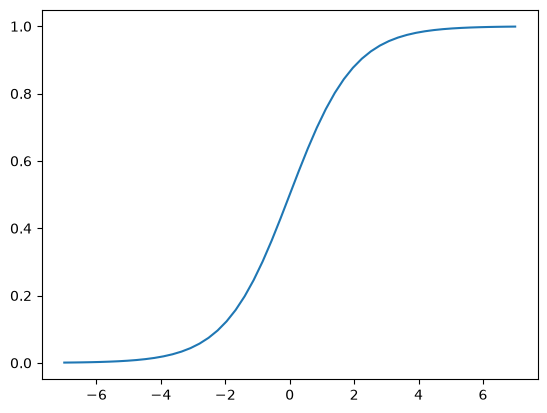

In [22]:
def sigmoid(z):
    return 1 / (1 + np.exp(-z))

def linear_regression(xi):
    result = w0

    for j in range(len(w)):
        result = result + xi[j] * w[j]

    return result

def logistic_regression(xi):
    score = w0

    for j in range(len(w)):
        score = score + xi[j] * w[j]

    result = sigmoid(score)
    return result

z = np.linspace(-7, 7, 51)
plt.plot(z, sigmoid(z))

## Training with Scikit-Learn

### Training

In [23]:
# Training The Model
model = LogisticRegression(max_iter=10000)
model.fit(X_train, y_train)

# Intercept (w0)
print("Intercept")
print(model.intercept_[0])

# The Weigths
print("\nWeigths")
print(model.coef_.round(3))

# Hard Predictions
print("\nHard Predictions")
print(model.predict(X_train))

# Probabilities (Left 0 Right 1)
print("\nProbabilities")
print(model.predict_proba(X_val))

Intercept
-0.046610508459345126

Weigths
[[ 0.681  0.034 -0.677  0.054 -0.016  0.112 -0.159  0.085  0.038 -0.
  -0.495  0.692 -0.159 -0.018 -0.188  0.068  0.158  0.116 -0.159  0.081
   0.283 -0.159 -0.086 -0.163  0.201 -0.045  0.083 -0.053 -0.004  0.107
  -0.012  0.068 -0.03   0.194 -0.095 -0.159  0.291 -0.055 -0.159  0.252
   0.233 -0.159 -0.037 -0.068  0.   ]]

Hard Predictions
[0 1 1 ... 1 0 1]

Probabilities
[[0.99331688 0.00668312]
 [0.79522073 0.20477927]
 [0.78237159 0.21762841]
 ...
 [0.84864556 0.15135444]
 [0.21116484 0.78883516]
 [0.18794568 0.81205432]]


### Validating

In [24]:
# Probabilities from Right (Being 1)
y_pred =  model.predict_proba(X_val)[:, 1]

# Clients with biggest Chance to Churn
churn_decision = (y_pred >= 0.5)
accuracy = (y_val == churn_decision).mean()

# Validating (Accuracy)
print(f'Accuracy  -> {accuracy:.2%}')

Accuracy  -> 80.34%


### Visualizing

In [25]:
df_pred = pd.DataFrame()
df_pred['probability'] = [f'{p:.2%}' for p in y_pred]
df_pred['prediction'] = churn_decision.astype(int)
df_pred['actual'] = y_val
df_pred['correct'] = df_pred['prediction'] == df_pred['actual']
df_pred

,probability,prediction,actual,correct
0,0.67%,0,0,True
1,20.48%,0,0,True
2,21.76%,0,0,True
3,56.42%,1,1,True
4,21.84%,0,0,True
...,...,...,...,...
1404,29.18%,0,0,True
1405,4.13%,0,1,False
1406,15.14%,0,0,True
1407,78.88%,1,1,True


## Model Interpretation

### Training Small Model

In [26]:
small = ['contract', 'tenure', 'monthlycharges']
dicts_train_small = df_train[small].to_dict(orient='records')
dicts_val_small = df_val[small].to_dict(orient='records')

dv_small = DictVectorizer(sparse=False)
dv_small.fit(dicts_train_small)

X_train_small = dv_small.transform(dicts_train_small)
model_small = LogisticRegression()
model_small.fit(X_train_small, y_train)

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following

### Getting Weigths

In [27]:
w0 = model_small.intercept_[0]
w = model_small.coef_[0]

print(f'Intercept -> {w0}')
print(f'Weigths -> {w}\n')

dict(zip(dv_small.get_feature_names_out(), w.round(3).tolist()))

Intercept -> -2.477957596026966
Weigths -> [ 0.9711394  -0.02379507 -0.94828863  0.02748534 -0.03619005]



{'contract=month-to-month': 0.971,
 'contract=one_year': -0.024,
 'contract=two_year': -0.948,
 'monthlycharges': 0.027,
 'tenure': -0.036}

### Interpretation

In [28]:
# Example of Client
# 1 Month of Contract | 50 Monthly Charges | 5 Tenure

probability = sigmoid(-2.47 + (1 * 0.971) + (0 * -0.024) + (0 * -0.948) + (50 * 0.027) + (5 * -0.036))
probability = f'{probability:.2%}'
print(probability)

41.85%
